In [1]:
import os
import sys
import json
import shutil
import hashlib
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

print(f"Python:     {sys.version.split()[0]}")
print(f"TensorFlow: {tf.__version__}")
print(f"Пристрої:   {tf.config.list_physical_devices()}")

FOOD_ROOT = Path("D:/Datasets/food-101")
assert (FOOD_ROOT / "meta/classes.txt").is_file(), "Не знайдено meta/classes.txt! Перевірте шлях."
assert (FOOD_ROOT / "meta/train.txt").is_file()
assert (FOOD_ROOT / "meta/test.txt").is_file()

n = 2
all_classes = sorted((FOOD_ROOT / "meta/classes.txt").read_text().splitlines())
assert len(all_classes) == 101

indices = [n - 1, n + 29, n + 59]
CLASS_NAMES = [all_classes[i] for i in indices]
print("Твої індекси та класи:", list(zip(indices, CLASS_NAMES)))
print("Мітки моделі:", dict(enumerate(CLASS_NAMES)))

Python:     3.11.9
TensorFlow: 2.21.0
Пристрої:   [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Твої індекси та класи: [(1, 'baby_back_ribs'), (31, 'donuts'), (61, 'lobster_roll_sandwich')]
Мітки моделі: {0: 'baby_back_ribs', 1: 'donuts', 2: 'lobster_roll_sandwich'}


In [2]:
X_demo = np.array([[1, 2, 0],
                   [0, 1, 3],
                   [2, 2, 1]], dtype="float32").reshape(1, 3, 3, 1)

K_demo = np.array([[1, 0],
                   [0, -1]], dtype="float32").reshape(2, 2, 1, 1)

conv_layer = layers.Conv2D(1, kernel_size=2, strides=1, padding="valid", use_bias=True)
_ = conv_layer(X_demo)
conv_layer.set_weights([K_demo, np.array([1.0], dtype="float32")])

out_linear = conv_layer(X_demo).numpy()[0, :, :, 0]
out_relu = tf.nn.relu(out_linear).numpy()

print("Вихід після згортки та bias=1:\n", out_linear)
print("Вихід після ReLU:\n", out_relu)
np.testing.assert_allclose(out_relu, np.array([[1., 0.], [0., 1.]]))
print("Перевірка ручного розрахунку пройдена!")

Вихід після згортки та bias=1:
 [[ 1.  0.]
 [-1.  1.]]
Вихід після ReLU:
 [[1. 0.]
 [0. 1.]]
Перевірка ручного розрахунку пройдена!


In [3]:
DATA_ROOT = Path("data/food101_lab9")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()

if not (DATA_ROOT / "manifest.json").exists():
    train_lines = (FOOD_ROOT / "meta/train.txt").read_text().splitlines()
    test_lines = (FOOD_ROOT / "meta/test.txt").read_text().splitlines()

    rng = np.random.default_rng(SEED)
    manifest = {"seed": SEED, "classes": CLASS_NAMES, "splits": {"train": [], "val": [], "test": []}}

    for cls in CLASS_NAMES:
        cls_train = [line for line in train_lines if line.startswith(f"{cls}/")]
        cls_test = [line for line in test_lines if line.startswith(f"{cls}/")]
        assert len(cls_train) == 750 and len(cls_test) == 250

        perm = rng.permutation(cls_train)
        val_ids = perm[:150]
        train_ids = perm[150:]

        split_map = {"train": train_ids, "val": val_ids, "test": cls_test}
        for part, ids in split_map.items():
            part_dir = DATA_ROOT / part / cls
            part_dir.mkdir(parents=True, exist_ok=True)
            for img_id in ids:
                src = FOOD_ROOT / "images" / f"{img_id}.jpg"
                dst = DATA_ROOT / part / f"{img_id}.jpg"
                if not dst.exists():
                    shutil.copy2(src, dst)
                manifest["splits"][part].append(dst.relative_to(DATA_ROOT / part).as_posix())

    (DATA_ROOT / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    Path("manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print("Дані скопійовано та manifest.json створено.")
else:
    manifest = json.loads((DATA_ROOT / "manifest.json").read_text(encoding="utf-8"))
    print("Підмножина вже існує, завантажено manifest.json.")

hashes = {}
for part in ["train", "val", "test"]:
    hashes[part] = {sha256_file(DATA_ROOT / part / rel): rel for rel in manifest["splits"][part]}
    print(f"{part.upper()}: {len(manifest['splits'][part])} зображень")

assert len(set(hashes["train"]).intersection(hashes["val"])) == 0
assert len(set(hashes["train"]).intersection(hashes["test"])) == 0
assert len(set(hashes["val"]).intersection(hashes["test"])) == 0
print("Перевірка SHA-256: точних дублікатів між train/val/test немає!")

Дані скопійовано та manifest.json створено.
TRAIN: 1800 зображень
VAL: 450 зображень
TEST: 750 зображень
Перевірка SHA-256: точних дублікатів між train/val/test немає!


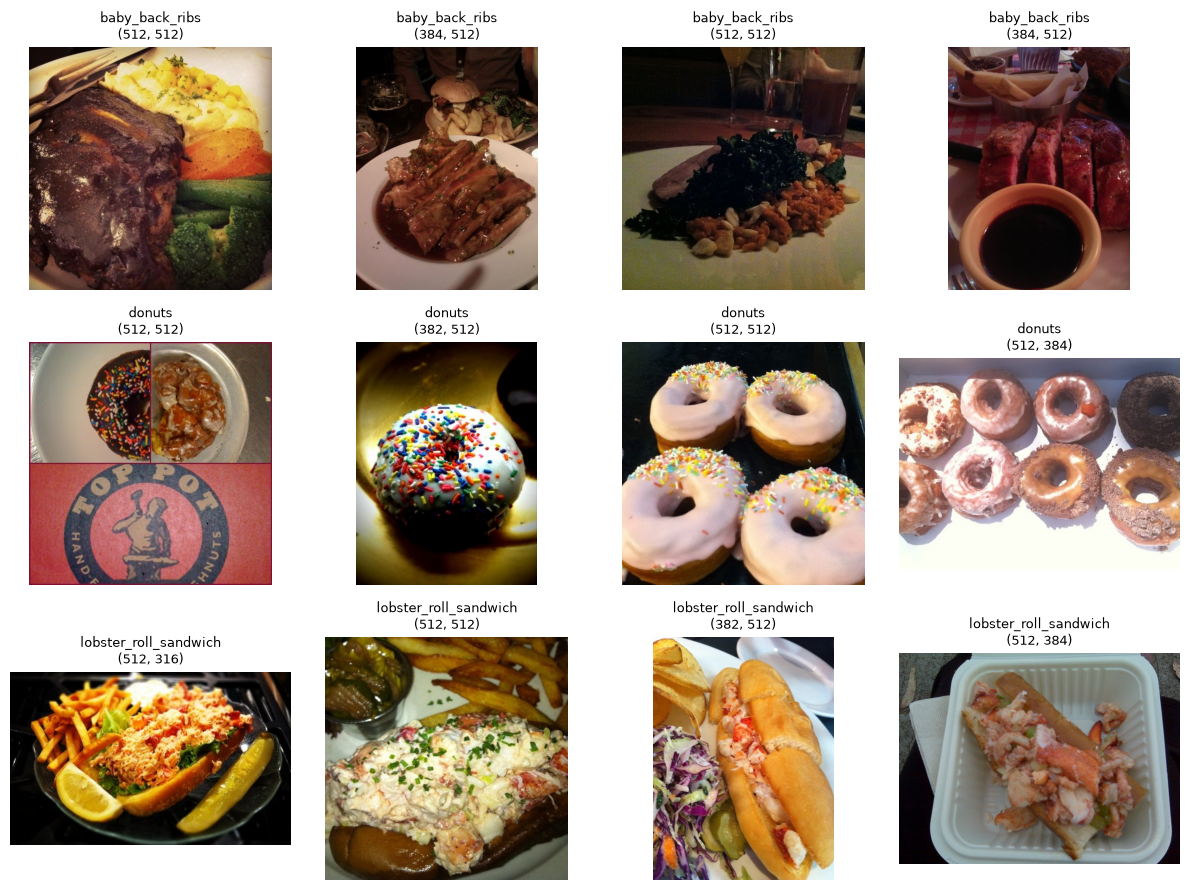

Found 1800 files belonging to 3 classes.
Found 450 files belonging to 3 classes.
Found 750 files belonging to 3 classes.
Форма батчу: (32, 128, 128, 3) (32,)
Діапазон пікселів: 0.0 — 255.0


In [4]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for row, cls in enumerate(CLASS_NAMES):
    cls_files = sorted((DATA_ROOT / "train" / cls).glob("*.jpg"))[:4]
    for col, img_path in enumerate(cls_files):
        img = Image.open(img_path)
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{cls}\n{img.size}", fontsize=9)
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "sample_images.png", dpi=200)
plt.show()

IMAGE_SIZE = (128, 128)

def load_split(part, training=False):
    return keras.utils.image_dataset_from_directory(
        DATA_ROOT / part,
        class_names=CLASS_NAMES,
        label_mode="int",
        color_mode="rgb",
        image_size=IMAGE_SIZE,
        batch_size=32,
        shuffle=training,
        seed=SEED
    )

train_ds = load_split("train", True).prefetch(tf.data.AUTOTUNE)
val_ds = load_split("val", False).prefetch(tf.data.AUTOTUNE)
test_ds = load_split("test", False).prefetch(tf.data.AUTOTUNE)

images, labels = next(iter(train_ds))
print("Форма батчу:", images.shape, labels.shape)
print("Діапазон пікселів:", float(tf.reduce_min(images)), "—", float(tf.reduce_max(images)))

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,779 (92.89 KB)

 Trainable params: 23,779 (92.89 KB)

 Non-trainable params: 0 (0.00 B)

--- Навчання базової CNN (dropout=0.0) ---
Epoch 1/30


d:\Data_Science_Labs\.venv-311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.4228 - loss: 1.0673 - val_accuracy: 0.5200 - val_loss: 1.0071
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.4800 - loss: 1.0163 - val_accuracy: 0.5356 - val_loss: 0.9908
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.5150 - loss: 0.9951 - val_accuracy: 0.5600 - val_loss: 0.9358
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.5567 - loss: 0.9436 - val_accuracy: 0.5244 - val_loss: 0.9234
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.5378 - loss: 0.9396 - val_accuracy: 0.5489 - val_loss: 0.9037
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.5711 - loss: 0.9123 - val_accuracy: 0.5867 - val_loss: 0.8987
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.5672 - loss: 0.9067 - val_accuracy: 0.6089 - val_loss: 0.8758
Epoch 8/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.5850 - loss: 0.8881 - val_accuracy: 0.6244 - val_loss: 0.

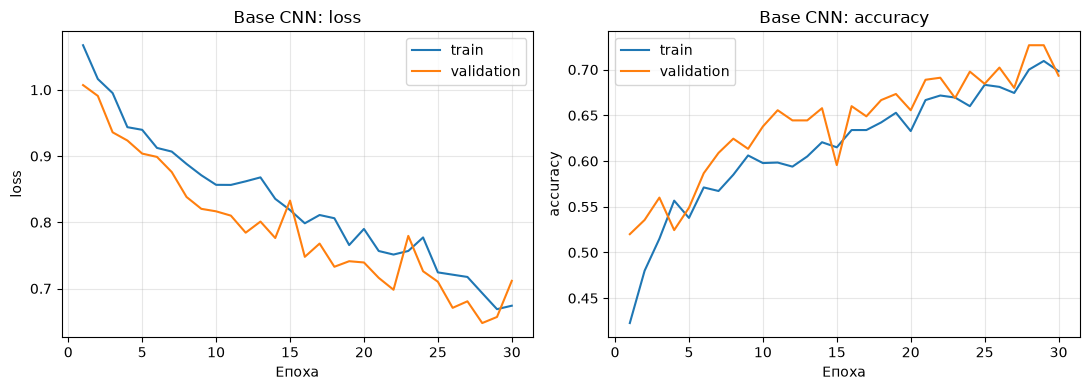

--- Навчання експериментальної CNN (dropout=0.3) ---
Found 1800 files belonging to 3 classes.
Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.4017 - loss: 1.0797 - val_accuracy: 0.5222 - val_loss: 1.0373
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.4850 - loss: 1.0222 - val_accuracy: 0.5200 - val_loss: 0.9640
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.5156 - loss: 0.9841 - val_accuracy: 0.4711 - val_loss: 0.9868
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.5289 - loss: 0.9570 - val_accuracy: 0.6222 - val_loss: 0.9019
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.5617 - loss: 0.9255 - val_accuracy: 0.6044 - val_loss: 0.8784
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.5567 - loss: 0.9255 - val_accuracy: 0.5978 - val_loss: 0.8702
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.5344 - loss: 0.9426 - val_accuracy: 0.5178 - val_loss: 0.9523
Epoch 8/30
57/57 

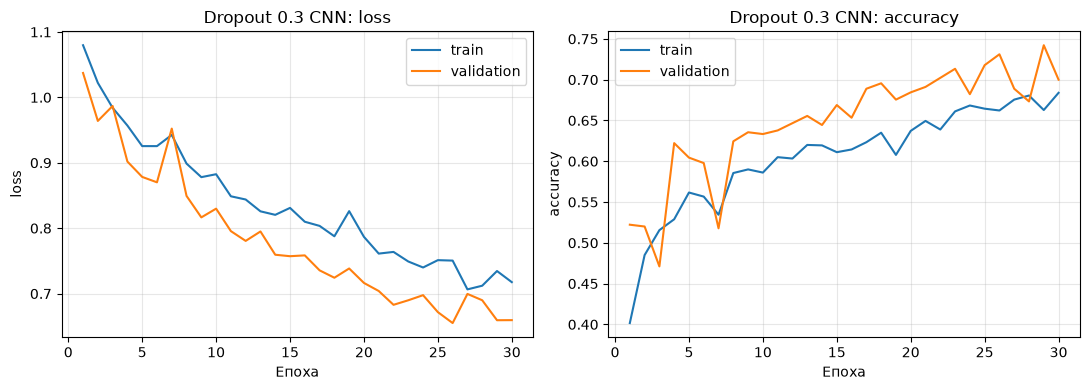

,Модель,Параметри,Епох,Найкраща епоха,Val Loss,Val Accuracy,Час (с)
0,Base CNN (dropout=0.0),23779,30,28,0.647844,0.726667,71.5
1,Experiment CNN (dropout=0.3),23779,30,26,0.655021,0.731111,73.5


Обрана за val_loss модель: Base CNN (dropout=0.0)


In [5]:
def make_model(dropout=0.0):
    inputs = keras.Input(shape=(128, 128, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)
    for i, filters in enumerate((16, 32, 64), 1):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=f"conv{i}")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(3, activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
    )
    return model

keras.utils.set_random_seed(SEED)
base_model = make_model(dropout=0.0)
base_model.summary()
assert base_model.count_params() == 23779

def fit_model(model):
    start_t = time.time()
    hist = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=30,
        callbacks=[
            keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
        ]
    )
    elapsed = time.time() - start_t
    return hist, elapsed

def plot_history(history, title_prefix, save_name):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    epochs = range(1, len(history.history["loss"]) + 1)
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs, history.history[metric], label="train")
        ax.plot(epochs, history.history["val_" + metric], label="validation")
        ax.set(xlabel="Епоха", ylabel=metric, title=f"{title_prefix}: {metric}")
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / save_name, dpi=200)
    plt.show()

print("--- Навчання базової CNN (dropout=0.0) ---")
base_history, base_time = fit_model(base_model)
base_val = base_model.evaluate(val_ds, verbose=0, return_dict=True)
plot_history(base_history, "Base CNN", "history_base.png")

print("--- Навчання експериментальної CNN (dropout=0.3) ---")
keras.utils.set_random_seed(SEED)
train_ds = load_split("train", True).prefetch(tf.data.AUTOTUNE)
changed_model = make_model(dropout=0.3)
changed_history, changed_time = fit_model(changed_model)
changed_val = changed_model.evaluate(val_ds, verbose=0, return_dict=True)
plot_history(changed_history, "Dropout 0.3 CNN", "history_dropout.png")

exp_df = pd.DataFrame([
    {
        "Модель": "Base CNN (dropout=0.0)",
        "Параметри": base_model.count_params(),
        "Епох": len(base_history.history["loss"]),
        "Найкраща епоха": int(np.argmin(base_history.history["val_loss"])) + 1,
        "Val Loss": base_val["loss"],
        "Val Accuracy": base_val["accuracy"],
        "Час (с)": round(base_time, 1)
    },
    {
        "Модель": "Experiment CNN (dropout=0.3)",
        "Параметри": changed_model.count_params(),
        "Епох": len(changed_history.history["loss"]),
        "Найкраща епоха": int(np.argmin(changed_history.history["val_loss"])) + 1,
        "Val Loss": changed_val["loss"],
        "Val Accuracy": changed_val["accuracy"],
        "Час (с)": round(changed_time, 1)
    }
])
exp_df.to_csv(RESULTS_DIR / "validation_experiments.csv", index=False)
display(exp_df)

if changed_val["loss"] < base_val["loss"]:
    selected_model = changed_model
    selected_name = "Experiment CNN (dropout=0.3)"
else:
    selected_model = base_model
    selected_name = "Base CNN (dropout=0.0)"

print("Обрана за val_loss модель:", selected_name)

Test результати (Base CNN (dropout=0.0)): {'accuracy': 0.7319999933242798, 'loss': 0.6398593187332153}

Classification Report (Dummy baseline accuracy = 0.3333):
                       precision    recall  f1-score   support

       baby_back_ribs       0.82      0.76      0.79       250
               donuts       0.63      0.66      0.65       250
lobster_roll_sandwich       0.75      0.78      0.77       250

             accuracy                           0.73       750
            macro avg       0.74      0.73      0.73       750
         weighted avg       0.74      0.73      0.73       750



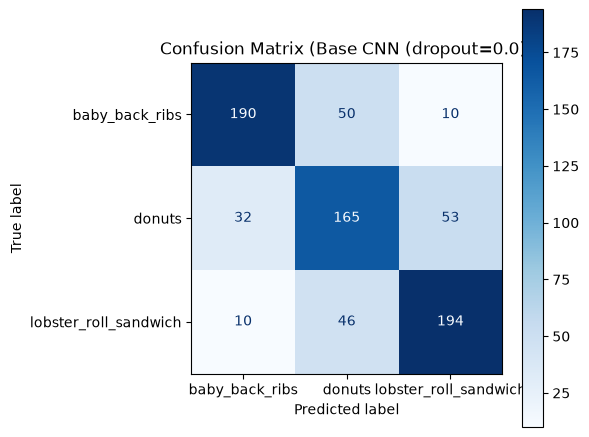

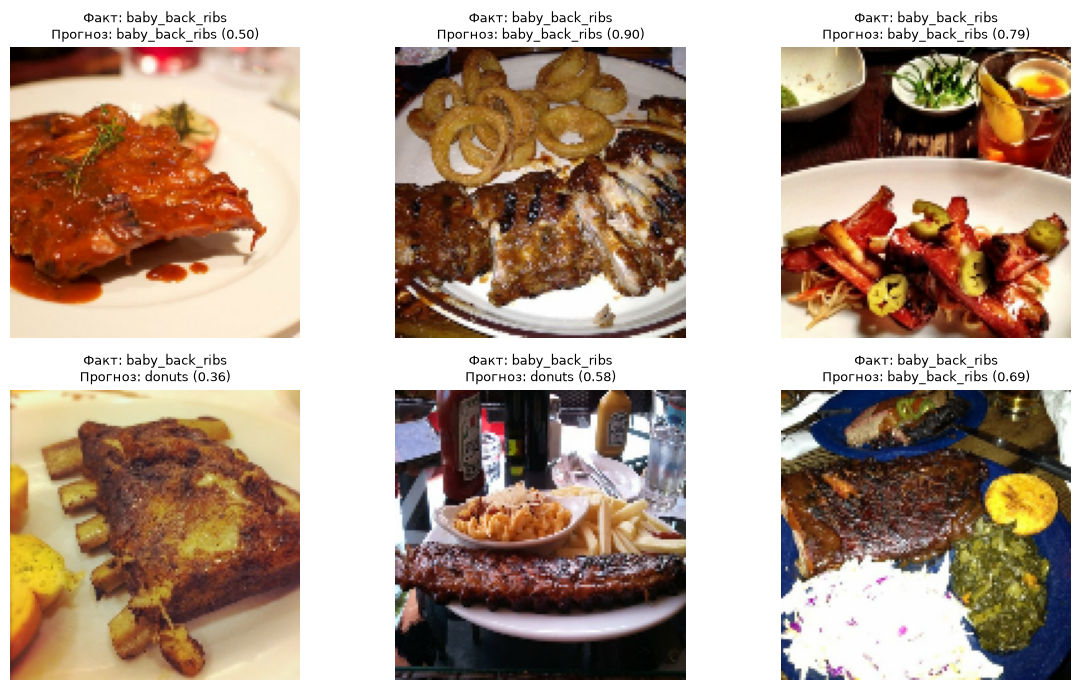

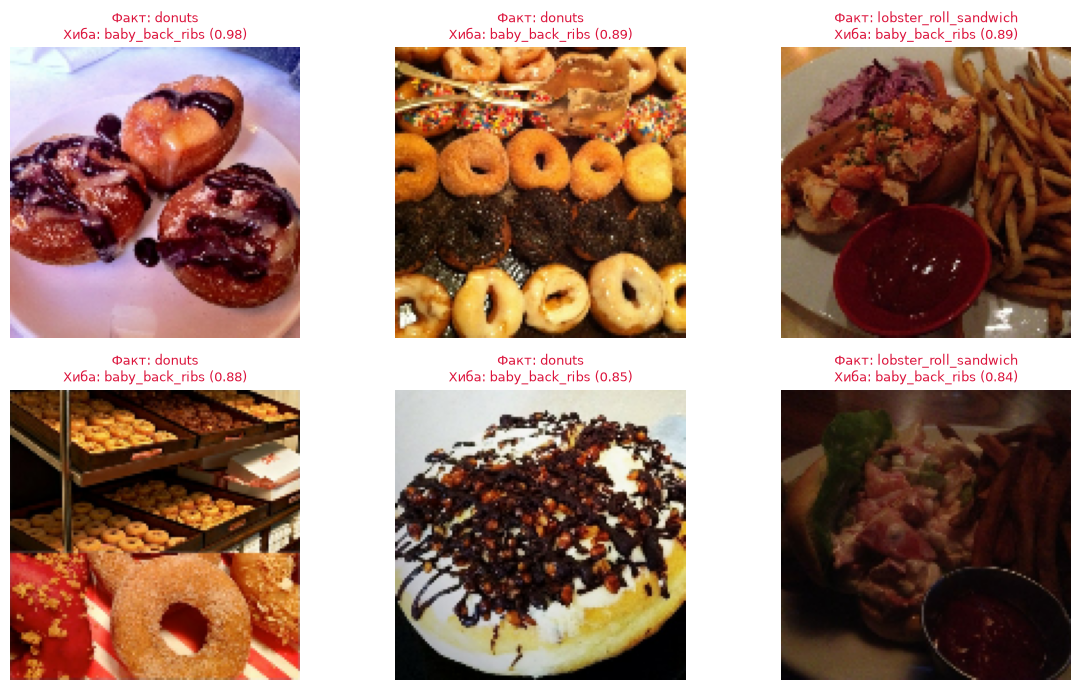

d:\Data_Science_Labs\.venv-311\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 128, 128, 3))
  warnings.warn(msg)


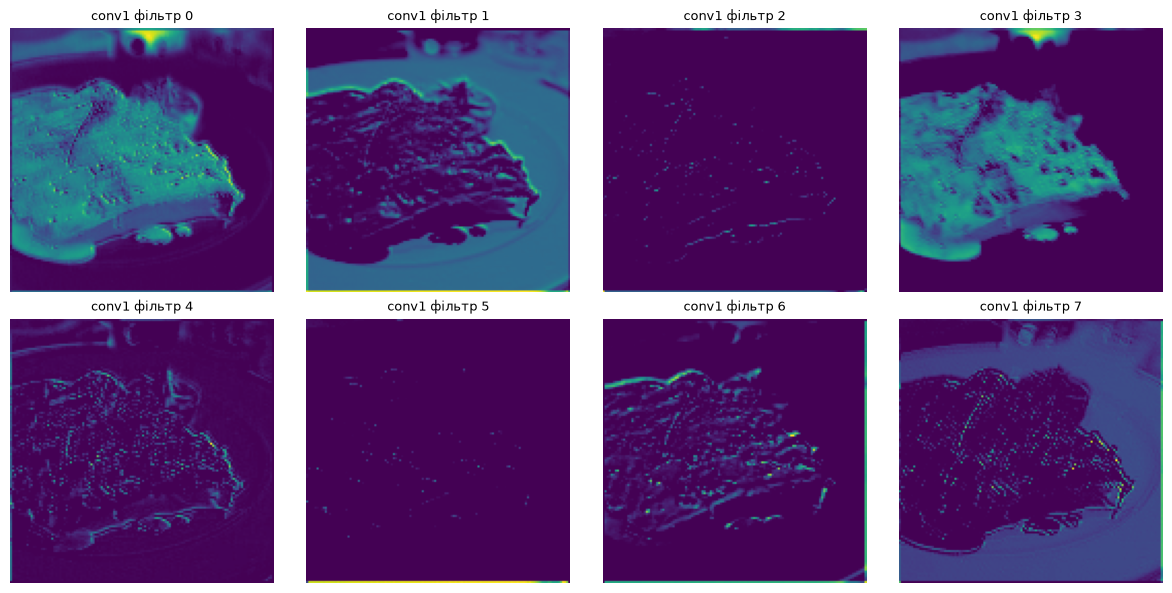

Модель food_cnn.keras та class_names.json збережено!


In [6]:
test_metrics = selected_model.evaluate(test_ds, verbose=0, return_dict=True)
print(f"Test результати ({selected_name}):", test_metrics)

y_true = np.concatenate([y.numpy() for _, y in test_ds])
all_images = np.concatenate([x.numpy() for x, _ in test_ds])
probabilities = selected_model.predict(test_ds, verbose=0)
y_pred = probabilities.argmax(axis=1)
confidences = probabilities.max(axis=1)

print("\nClassification Report (Dummy baseline accuracy = 0.3333):")
print(classification_report(y_true, y_pred, labels=[0, 1, 2], target_names=CLASS_NAMES, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=[0, 1, 2], display_labels=CLASS_NAMES, ax=ax, cmap="Blues")
plt.title(f"Confusion Matrix ({selected_name})")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=200)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for idx, ax in enumerate(axes.flat):
    ax.imshow(all_images[idx].astype("uint8"))
    ax.set_title(f"Факт: {CLASS_NAMES[y_true[idx]]}\nПрогноз: {CLASS_NAMES[y_pred[idx]]} ({confidences[idx]:.2f})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "sample_predictions.png", dpi=200)
plt.show()

wrong_idx = np.flatnonzero(y_pred != y_true)
if len(wrong_idx) > 0:
    top_wrong = wrong_idx[np.argsort(confidences[wrong_idx])[::-1]][:6]
    fig, axes = plt.subplots(2, 3, figsize=(12, 7))
    for i, ax in enumerate(axes.flat):
        if i < len(top_wrong):
            w = top_wrong[i]
            ax.imshow(all_images[w].astype("uint8"))
            ax.set_title(f"Факт: {CLASS_NAMES[y_true[w]]}\nХиба: {CLASS_NAMES[y_pred[w]]} ({confidences[w]:.2f})", fontsize=9, color="crimson")
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "error_examples.png", dpi=200)
    plt.show()

feature_model = keras.Model(selected_model.inputs, selected_model.get_layer("conv1").output)
feature_maps = feature_model(all_images[:1], training=False).numpy()

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[0, :, :, i], cmap="viridis")
    ax.set_title(f"conv1 фільтр {i}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "conv1_feature_maps.png", dpi=200)
plt.show()

selected_model.save("food_cnn.keras")
Path("class_names.json").write_text(json.dumps(CLASS_NAMES, ensure_ascii=False, indent=2), encoding="utf-8")
print("Модель food_cnn.keras та class_names.json збережено!")

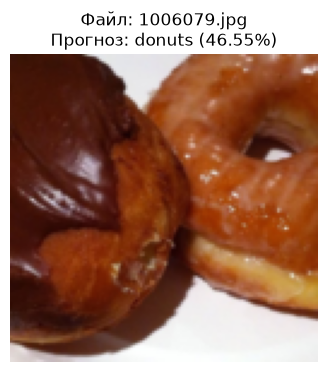

In [7]:
# Перевірка відновлення моделі та точковий прогноз окремого зображення
restored_model = keras.models.load_model("food_cnn.keras")
loaded_classes = json.loads(Path("class_names.json").read_text(encoding="utf-8"))

# Беремо довільне фото (можна замінити шлях на власне фото страви з диску)
sample_path = next((DATA_ROOT / "test" / loaded_classes[1]).glob("*.jpg"))

img = keras.utils.load_img(sample_path, target_size=(128, 128), interpolation="bilinear")
img_array = keras.utils.img_to_array(img)
img_batch = np.expand_dims(img_array, axis=0)  # (1, 128, 128, 3)

probs = restored_model.predict(img_batch, verbose=0)[0]
pred_idx = int(np.argmax(probs))

plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.title(f"Файл: {sample_path.name}\nПрогноз: {loaded_classes[pred_idx]} ({probs[pred_idx]:.2%})")
plt.axis("off")
plt.savefig(RESULTS_DIR / "single_image_prediction.png", dpi=200)
plt.show()